In [52]:
import matplotlib.pyplot as plt
import numpy as np
import os
import pandas as pd
from pathlib import Path
import seaborn as sns
from pathlib import Path
import sys

from utils import pq_to_xy, plot_spatial_kernel_hex
from utils.spatial_RF import compute_kernel
from utils.plotting import plot_example_RFs, plot_kernels_on_eye, receptive_fields_grid


In [ ]:
from utils.io import load_columnar_connectome
edges, nodes_df = load_columnar_connectome(norm=True)
print("Available celltypes")
print("Number: ", nodes_df['cell_type'].nunique())
print(nodes_df['cell_type'].unique())

Available celltypes
Number:  24
['C2' 'C3' 'L1' 'L2' 'L3' 'L5' 'Mi1' 'Mi4' 'Mi9' 'T1' 'Tm1' 'Tm2' 'Tm20'
 'Tm4' 'Tm9' 'T4a' 'T4b' 'T4c' 'T4d' 'T5a' 'T5b' 'T5c' 'T5d' 'CT1']


In [54]:
edges['count'].min()


np.int64(5)

## Variability in a single pair of two types

In [55]:
### GLOBAL VARIABLES
PRE_TYPE  = 'Tm9'
POST_TYPE = 'T5b'
RADIUS    = 2
SEED      = 1

In [56]:
mean_kernel, pair_kernels = compute_kernel(
    edges,
    pre_type    = PRE_TYPE,
    post_type   = POST_TYPE,
    radius      = RADIUS)

pair_kernels

,post,target_p,target_q,post_side,dp,dq,count,signed_count,source_p,source_q,pre_cell_type,post_cell_type
0,98389,6.0,-10.0,right,-2,-2,0.0,0.0,4.0,-12.0,Tm9,T5b
1,98389,6.0,-10.0,right,-2,-1,0.0,0.0,4.0,-11.0,Tm9,T5b
2,98389,6.0,-10.0,right,-2,0,0.0,0.0,4.0,-10.0,Tm9,T5b
3,98389,6.0,-10.0,right,-1,-2,13.0,13.0,5.0,-12.0,Tm9,T5b
4,98389,6.0,-10.0,right,-1,-1,0.0,0.0,5.0,-11.0,Tm9,T5b
...,...,...,...,...,...,...,...,...,...,...,...,...
16411,160169,-14.0,-3.0,right,1,1,0.0,0.0,-13.0,-2.0,Tm9,T5b
16412,160169,-14.0,-3.0,right,1,2,0.0,0.0,-13.0,-1.0,Tm9,T5b
16413,160169,-14.0,-3.0,right,2,0,0.0,0.0,-12.0,-3.0,Tm9,T5b
16414,160169,-14.0,-3.0,right,2,1,0.0,0.0,-12.0,-2.0,Tm9,T5b


/home/guardomayas/NUIN/sjbcs/male_cns_var/utils/plotting.py:274: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 0.88, 1]) #[left, bottom, right, top]


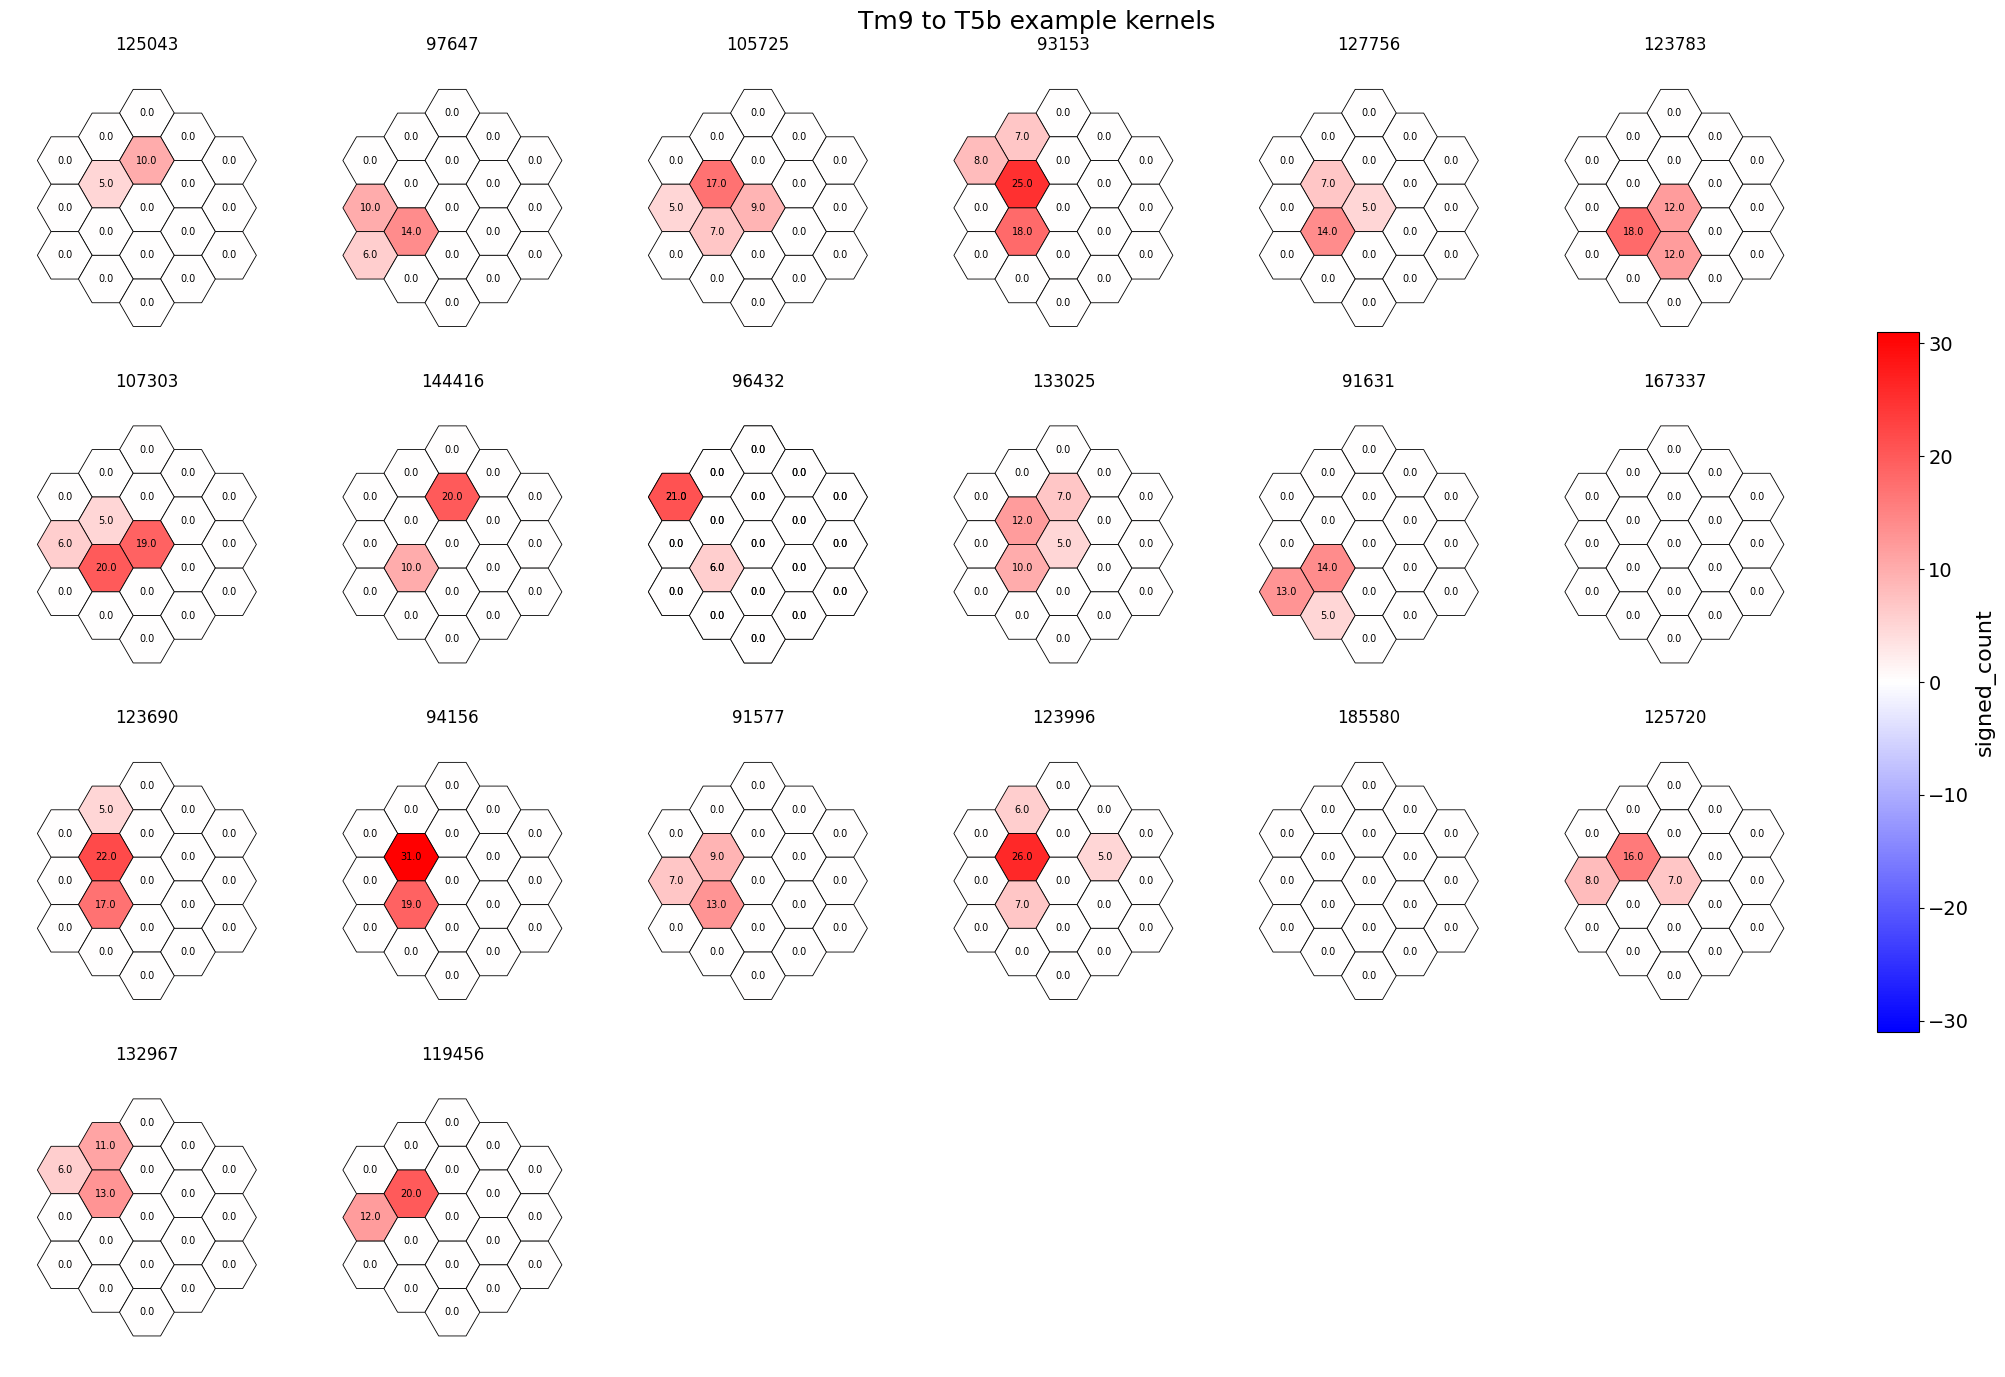

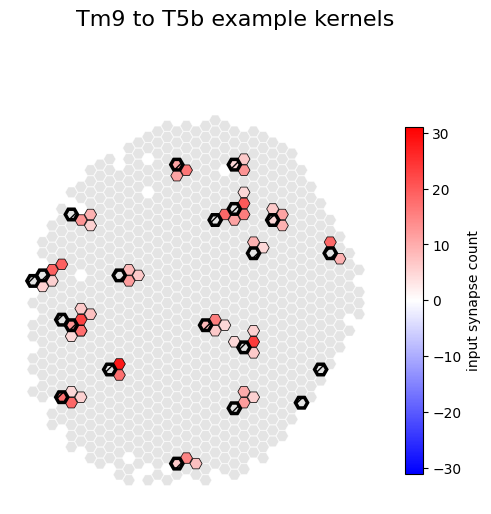

In [57]:
n_samples = 20
plot_example_RFs(pair_kernels, 
                n_samples = n_samples,
                max_cols = 6,
                seed=SEED
                 )

plot_kernels_on_eye(pair_kernels, 
                    n_samples, 
                    size=(6,6),
                    seed=SEED)

<Axes: title={'center': 'Tm9 to T5b mean kernel'}>

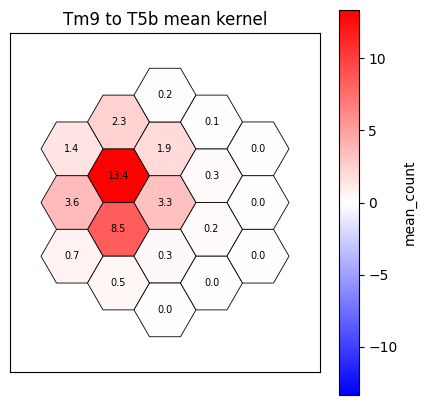

In [58]:
###How do this kernels vary?
## Mean kernel tells us the shared/common motifs
title = (f"{pair_kernels['pre_cell_type'].iloc[0]} to "
      f"{pair_kernels['post_cell_type'].iloc[0]} mean kernel")
plot_spatial_kernel_hex(mean_kernel, 
                        value_col="mean_count", 
                        radius=RADIUS, 
                        add_colorbar=True, 
                        title= title)

In [59]:
### Matrix form
pair_Matrix = (
        pair_kernels
        .assign(                    ##Creates new col called offset: converts the (dp,dq) pair into a col name
            offset=lambda d: (
                d["dp"].astype(int).astype(str)
                + "_"
                + d["dq"].astype(int).astype(str)
            )
        )
        .pivot_table( #reshapes the long table into a wide matrix.
            index="post", #row per post
            columns="offset", #one col per offset
            values="count", #fills each col with summed counts
            aggfunc="sum", #If there are multiple rows with the same (post, offset), add their counts together. I think there should be few
            fill_value=0,
        ).rename_axis(columns=None)   # removes the "offset" label above columns
    # .reset_index()               # turns post from index into first column
    )
pair_Matrix_table = pair_Matrix.reset_index() # for saving and sutff
pair_Matrix

,-1_-1,-1_-2,-1_0,-1_1,-2_-1,-2_-2,-2_0,0_-1,0_-2,0_0,0_1,0_2,1_-1,1_0,1_1,1_2,2_0,2_1,2_2
post,,,,,,,,,,,,,,,,,,,
80374,0.0,6.0,0.0,0.0,0.0,0.0,0.0,24.0,0.0,0.0,5.0,0.0,0.0,36.0,0.0,0.0,0.0,0.0,0.0
81491,0.0,0.0,0.0,0.0,0.0,0.0,0.0,16.0,7.0,0.0,0.0,0.0,5.0,10.0,0.0,0.0,0.0,0.0,0.0
81721,0.0,0.0,0.0,0.0,0.0,0.0,0.0,15.0,0.0,15.0,0.0,0.0,0.0,15.0,0.0,0.0,0.0,0.0,0.0
83167,9.0,0.0,0.0,0.0,0.0,0.0,0.0,12.0,0.0,6.0,0.0,0.0,0.0,7.0,0.0,0.0,0.0,0.0,0.0
83175,14.0,7.0,0.0,0.0,0.0,0.0,0.0,7.0,0.0,7.0,0.0,0.0,0.0,17.0,0.0,0.0,0.0,0.0,0.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
206612,0.0,10.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,13.0,0.0,0.0,0.0,0.0,6.0,0.0,0.0,0.0,0.0
220122,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,5.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
545103,0.0,15.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,9.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [60]:
# mean_vec = pair_Matrix.mean(axis=0) ### Mean kernel 
# for offset, mean_count in mean_vec.items():
#     print(offset, mean_count)

In [61]:
## Convert from matrix form back to df for plotting
def vector_to_kernel(vec, value_name="value"):
    rows = []
    for offsets, count in vec.items():
        dp, dq = offsets.split("_")
        rows.append({
            "dp": int(dp),
            "dq": int(dq),
            value_name: count,
        })

    return pd.DataFrame(rows)

/tmp/ipykernel_20512/558269356.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  fig.tight_layout()


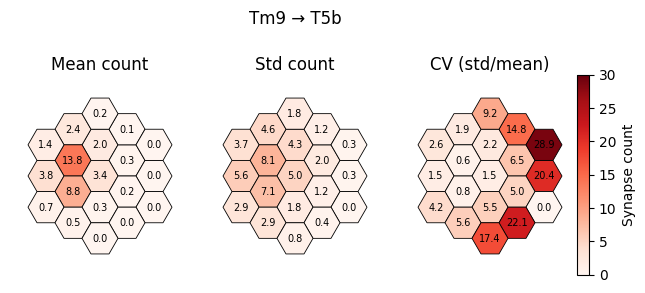

In [62]:
from matplotlib.colors import TwoSlopeNorm,  Normalize

mean_vec = pair_Matrix.mean(axis=0)
std_vec = pair_Matrix.std(axis=0)
var_vec = pair_Matrix.var(axis=0)
cv_vec = std_vec / mean_vec.replace(0, np.nan)
cv_vec = cv_vec.fillna(0)

maps = {
    "Mean count": mean_vec,
    "Std count": std_vec,
    # "Variance (Sqrd units)": var_vec,
    "CV (std/mean)": cv_vec,
}
# norm = TwoSlopeNorm(
#         vmin=-55,
#         vcenter=0,
#         vmax=55
#     )

norm = Normalize(vmin=0, vmax= 30)
CMAP = "Reds"

fig, axes = plt.subplots(1,3,  figsize= (6,5))
fig.suptitle(f"{PRE_TYPE} → {POST_TYPE}", y=0.8)
axes = axes.ravel()  # turns 2x2 array into flat list of 4 axes
for ax, (title, vec) in zip(axes, maps.items()):
    ax.axis("off")
    kernel = vector_to_kernel(vec, value_name="value")
    plot_spatial_kernel_hex(kernel, 
                            ax=ax, 
                            value_col="value", 
                            norm = norm,
                            cmap = CMAP,
                            radius=RADIUS)
    ax.set_title(title)

# Common colorbar
sm = plt.cm.ScalarMappable(norm=norm, cmap=plt.get_cmap(f"{CMAP}"))
sm.set_array([])

cax = fig.add_axes([0.97, 0.27, 0.02, 0.4]) # [left, bottom, width, height]
cbar = fig.colorbar(
    sm,
    cax=cax,
    shrink=0.4,
    location="right",
    label="Synapse count"
)

fig.tight_layout()
plt.show()

In [63]:
from sklearn.decomposition import PCA, TruncatedSVD

X = pair_Matrix.copy()
# X = X.div(
#     X.abs().sum(axis=1).replace(0, np.nan),
#     axis=0
# ).fillna(0)
pca = PCA(n_components=19)  

Z_pca = pca.fit_transform(X)   # scores: PC coordinates of each T4/5 cell

V_pca = pd.DataFrame(   #PC loading vectors / eigenvectors over offsets
    pca.components_,
    columns=X.columns,
    index=[f"PC{i+1}" for i in range(pca.n_components_)]
)

mu_pca = pd.Series(
    pca.mean_,
    index=X.columns,
    name="mean_kernel"
)

lambdas_pca = pd.Series( #variance explained by each PC / eigenvalues
    pca.explained_variance_,
    index=V_pca.index,
    name="eigenvalue"
)

explained_pca = pd.Series( #fraction of total variance explained by each PC
    pca.explained_variance_ratio_,
    index=V_pca.index,
    name="explained_variance_ratio"
)

scores_pca = pd.DataFrame(
    Z_pca,
    index=X.index,
    columns=V_pca.index
)

# Uncentered decomposition: raw motifs
svd = TruncatedSVD(n_components=19, random_state=0)
Z_svd = svd.fit_transform(X)

V_svd = pd.DataFrame(
    svd.components_,
    columns=X.columns,
    index=[f"SVD{i+1}" for i in range(svd.n_components)]
)

scores_svd = pd.DataFrame(
    Z_svd,
    index=X.index,
    columns=V_svd.index
)

energy = pd.Series(
    svd.singular_values_**2,
    index=V_svd.index,
    name="raw_energy"
)

energy_ratio = energy / energy.sum()
energy_ratio.name = "raw_energy_ratio"

explained_svd = pd.Series(
    svd.explained_variance_ratio_,
    index=V_svd.index,
    name="explained_variance_ratio"
)

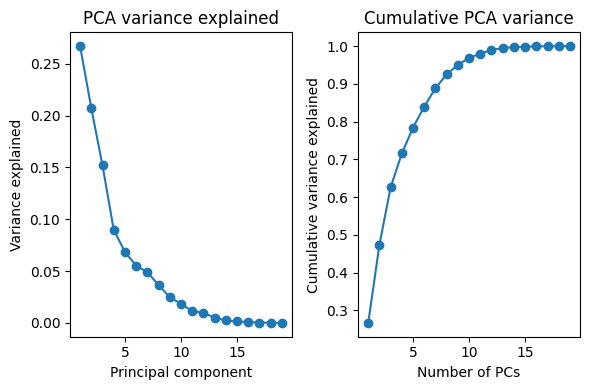

In [64]:
fig, axes = plt.subplots(1, 2, figsize=(6, 4))

pc_nums = np.arange(1, len(explained_pca) + 1)

axes[0].plot(pc_nums, explained_pca  , marker="o")
axes[0].set_xlabel("Principal component")
axes[0].set_ylabel("Variance explained")
axes[0].set_title("PCA variance explained")

axes[1].plot(pc_nums, explained_pca.cumsum(), marker="o")
axes[1].set_xlabel("Number of PCs")
axes[1].set_ylabel("Cumulative variance explained")
axes[1].set_title("Cumulative PCA variance")

# show fewer ticks
# tick_step = 2  # or 3, depending on how crowded it is
# for ax in axes:
#     ax.set_xticks(pc_nums[::tick_step])
#     ax.tick_params(axis="x", rotation=45)

fig.tight_layout()
plt.show()

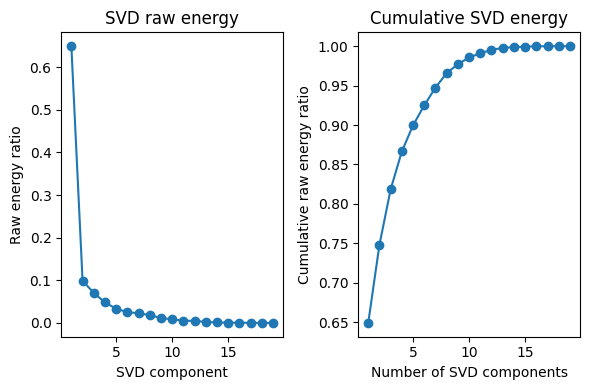

In [65]:
fig, axes = plt.subplots(1, 2, figsize=(6, 4))

sv_nums = np.arange(1, len(energy_ratio) + 1)

axes[0].plot(sv_nums, energy_ratio, marker="o")
axes[0].set_xlabel("SVD component")
axes[0].set_ylabel("Raw energy ratio")
axes[0].set_title("SVD raw energy")

axes[1].plot(sv_nums, energy_ratio.cumsum(), marker="o")
axes[1].set_xlabel("Number of SVD components")
axes[1].set_ylabel("Cumulative raw energy ratio")
axes[1].set_title("Cumulative SVD energy")

# for ax in axes:
#     ax.set_xticks(sv_nums[::4])

fig.tight_layout()
plt.show()

In [66]:
# pd.set_option('display.max_columns', 10)
# df = V_svd.copy()
# df["magnitude"] = np.linalg.norm(V_svd, axis=1)
# df

/tmp/ipykernel_20512/364436554.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


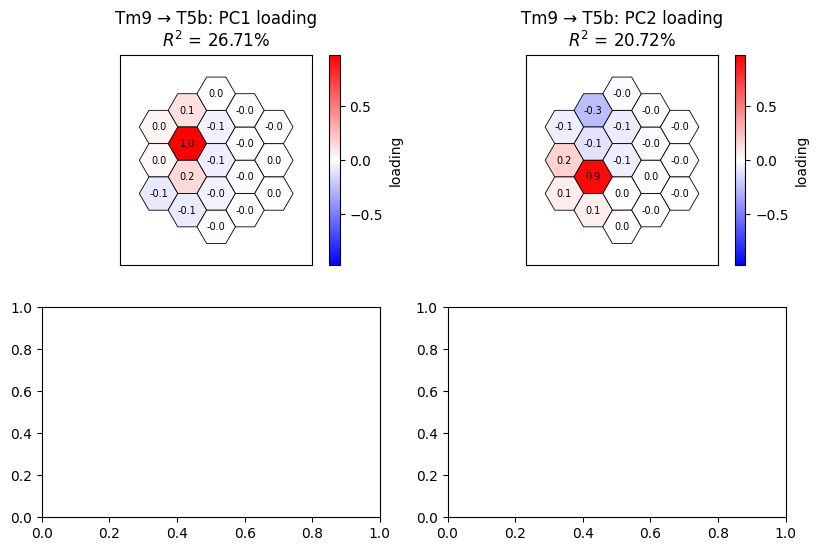

In [67]:
from cmath import exp

n_show =2

pc_global_vmax = np.abs(V_pca.iloc[:6].values).max()
fig, axes = plt.subplots(2, n_show, figsize=(8*1.2, 5*1.2))
for i, ax in zip(range(n_show), axes.flat):
    pc_name = V_pca.index[i]
    kernel = vector_to_kernel(V_pca.loc[pc_name], value_name="loading")

    plot_spatial_kernel_hex(
        kernel,
        value_col="loading",
        radius=RADIUS,
        norm=TwoSlopeNorm(vcenter=0, vmin=-pc_global_vmax, vmax=pc_global_vmax),
        add_colorbar=True,
        ax=ax
    )
    ax.set_title(
        f"{PRE_TYPE} → {POST_TYPE}: {pc_name} loading\n"
        fr"$R^2$ = {explained_pca.iloc[i]:.2%}"
    )
fig.show()

/tmp/ipykernel_20512/307513681.py:22: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


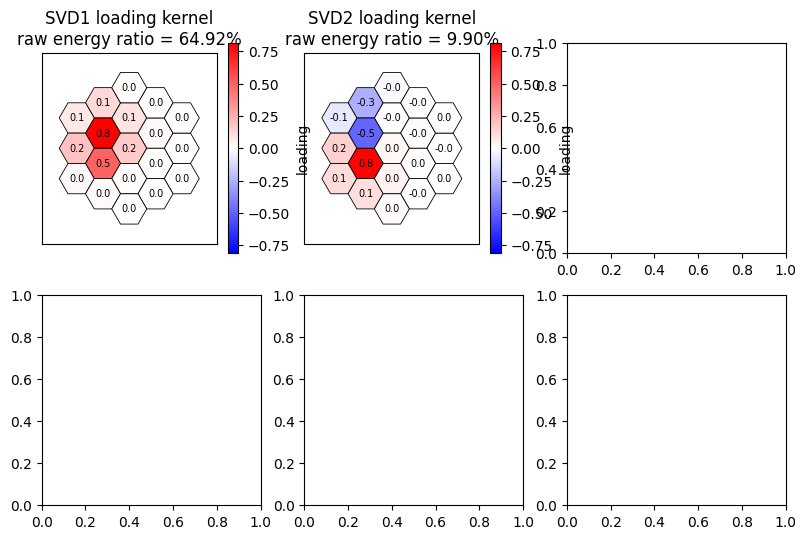

In [68]:
n_show = 2
global_vmax = np.abs(V_svd.iloc[:n_show].values).max()

fig, axes = plt.subplots(2, 3, figsize=(8*1.2, 5*1.2))
for i, ax in zip(range(n_show), axes.flat):
    sv_name = V_svd.index[i]   # "SVD1", "SVD2", ...
    kernel = vector_to_kernel(V_svd.loc[sv_name], value_name="loading")

    plot_spatial_kernel_hex(
        kernel,
        value_col="loading",
        radius=RADIUS,
        norm=TwoSlopeNorm(vcenter=0, vmin=-global_vmax, vmax=global_vmax),
        add_colorbar=True,
        ax=ax
    )

    ax.set_title(
        f"{sv_name} loading kernel\n"
        f"raw energy ratio = {energy_ratio.iloc[i]:.2%}"
    )
fig.show()


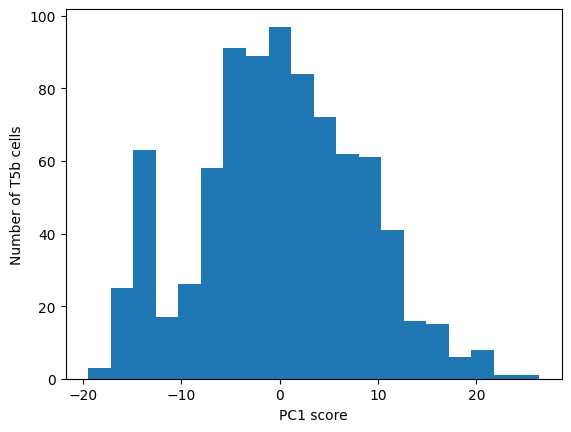

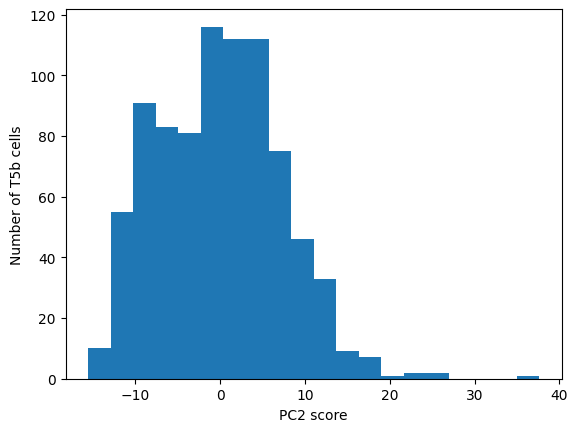

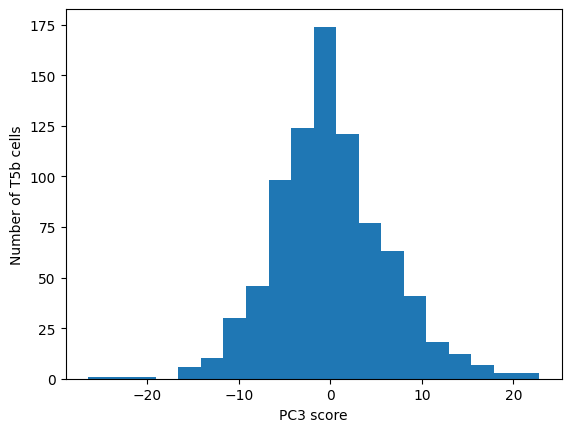

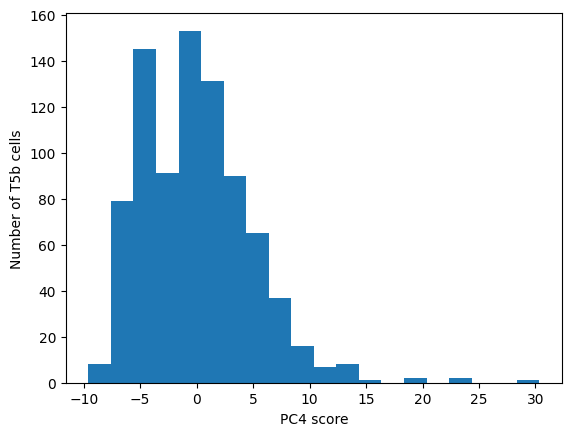

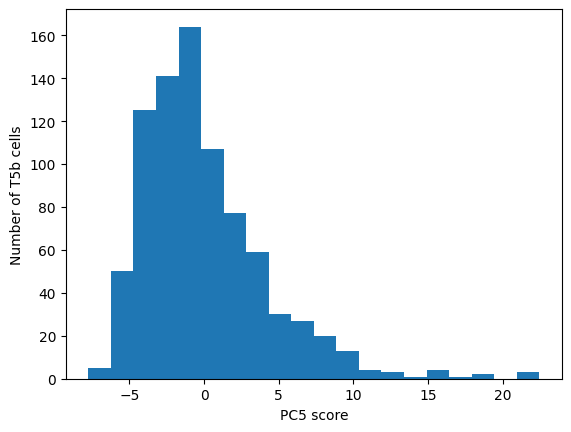

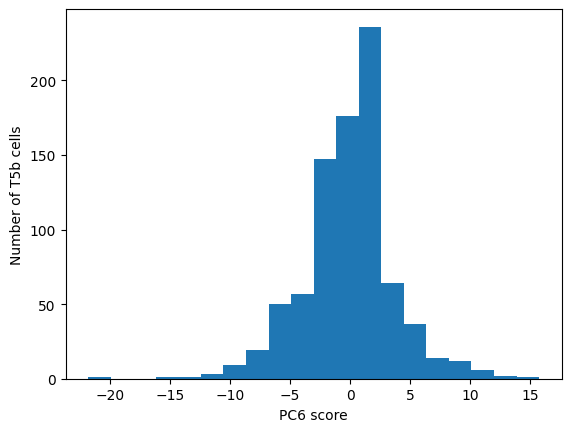

In [69]:
for i in range(6):
    pc_name = V_pca.index[i]    
    plt.hist(scores_pca[pc_name], bins=20)
    plt.xlabel(f"{pc_name} score")
    plt.ylabel("Number of T5b cells")
    plt.show()

In [70]:
total_input = pair_Matrix.sum(axis=1)
pc_total_corr = pd.DataFrame({
    "pearson_r": scores_pca.corrwith(total_input),
    "explained_variance_ratio": explained_pca,
})

pc_total_corr["abs_r"] = pc_total_corr["pearson_r"].abs()

pc_total_corr.sort_values("abs_r", ascending=False)
spearman_corrs = scores_pca.corrwith(total_input, method="spearman")

pc_total_corr["spearman_r"] = spearman_corrs
pc_total_corr

,pearson_r,explained_variance_ratio,abs_r,spearman_r
PC1,0.511375,0.267098,0.511375,0.561928
PC2,0.307559,0.207225,0.307559,0.290166
PC3,-0.164233,0.151928,0.164233,-0.187558
PC4,0.438006,0.089842,0.438006,0.426597
PC5,0.397659,0.068483,0.397659,0.392037
PC6,-0.058536,0.055342,0.058536,-0.020032
PC7,0.128537,0.048905,0.128537,0.106953
PC8,0.422615,0.036643,0.422615,0.466580
PC9,-0.020046,0.024848,0.020046,0.069370
PC10,0.205424,0.018485,0.205424,0.277652


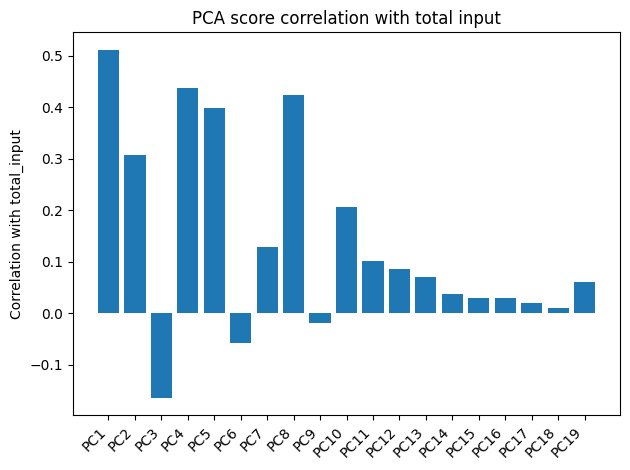

In [71]:
total_input = pair_Matrix.sum(axis=1)
total_input.name = "total_input"
corrs = scores_pca.corrwith(total_input)
plt.bar(corrs.index, corrs.values)
plt.xticks(rotation=45, ha="right")

plt.ylabel("Correlation with total_input")
plt.title("PCA score correlation with total input")
plt.tight_layout()
plt.show()

In [72]:
total_input

post
80374     71.0
81491     38.0
81721     45.0
83167     34.0
83175     52.0
          ... 
206612    29.0
220122     5.0
545103    24.0
545194    26.0
555697    33.0
Name: total_input, Length: 836, dtype: float64

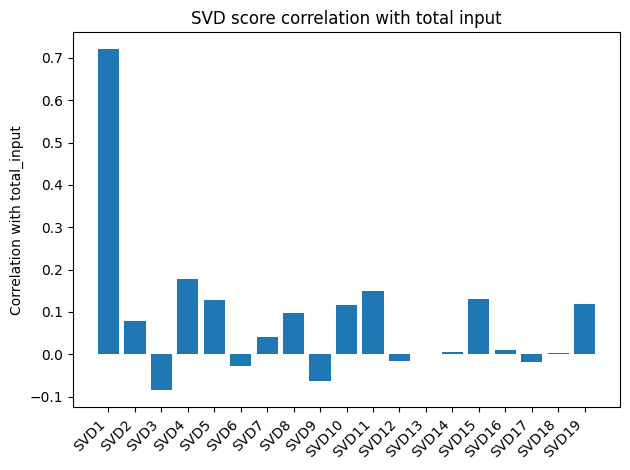

In [73]:
total_input = pair_Matrix.sum(axis=1)
total_input.name = "total_input"
corrs = scores_svd.corrwith(total_input)
plt.bar(corrs.index, corrs.values)
plt.xticks(rotation=45, ha="right")

plt.ylabel("Correlation with total_input")
plt.title("SVD score correlation with total input")
plt.tight_layout()
plt.show()

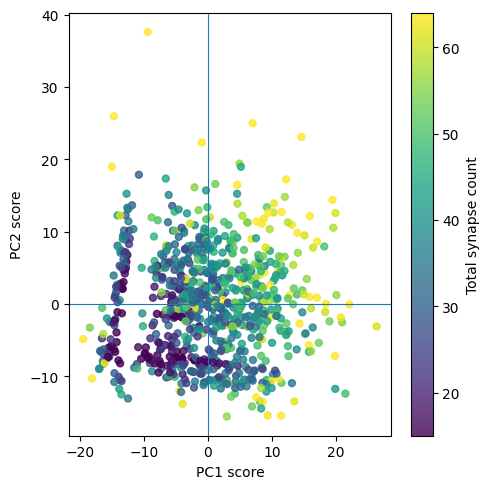

In [74]:
color_vals = total_input.loc[scores_pca.index]

vmin = np.percentile(color_vals, 5)
vmax = np.percentile(color_vals, 95)

plt.figure(figsize=(5, 5))

sc = plt.scatter(
    scores_pca["PC1"],
    scores_pca["PC2"],
    c=color_vals,
    s=25,
    alpha=0.8,
    vmin=vmin,
    vmax=vmax,
)

plt.axhline(0, linewidth=0.8)
plt.axvline(0, linewidth=0.8)

plt.xlabel("PC1 score")
plt.ylabel("PC2 score")

plt.colorbar(sc, label="Total synapse count")
plt.tight_layout()
plt.show()

/tmp/ipykernel_20512/4210004023.py:22: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.xlabel(f"PC1 ({explained_pca[0]*100:.1f}%)")
/tmp/ipykernel_20512/4210004023.py:23: FutureWarning: Series.__getitem__ treating keys as positions is deprecated. In a future version, integer keys will always be treated as labels (consistent with DataFrame behavior). To access a value by position, use `ser.iloc[pos]`
  plt.ylabel(f"PC2 ({explained_pca[1]*100:.1f}%)")


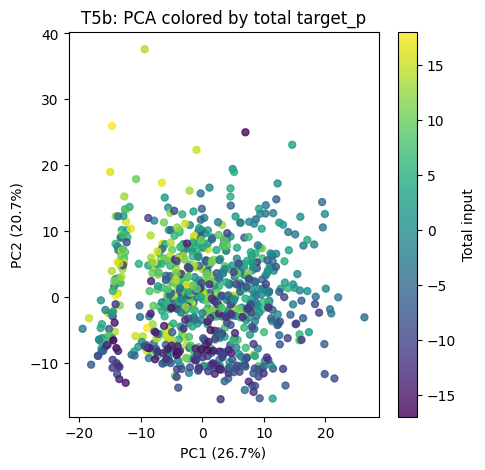

In [75]:
meta = (
    edges
    .query("post_cell_type == @POST_TYPE")
    [["post", "post_cell_type", "target_p", "target_q"]]
    .drop_duplicates("post")
    .set_index("post")
)

pca_meta = scores_pca.join(meta, how="left")

total_input = pair_Matrix.abs().sum(axis=1)
pca_meta["total_input"] = total_input
plt.figure(figsize=(5, 5))
sc = plt.scatter(
    pca_meta["PC1"],
    pca_meta["PC2"],
    c=pca_meta["target_p"],
    s=25,
    alpha=0.8,
)
plt.colorbar(sc, label="Total input")
plt.xlabel(f"PC1 ({explained_pca[0]*100:.1f}%)")
plt.ylabel(f"PC2 ({explained_pca[1]*100:.1f}%)")
plt.title(f"{POST_TYPE}: PCA colored by total target_p")
plt.show()

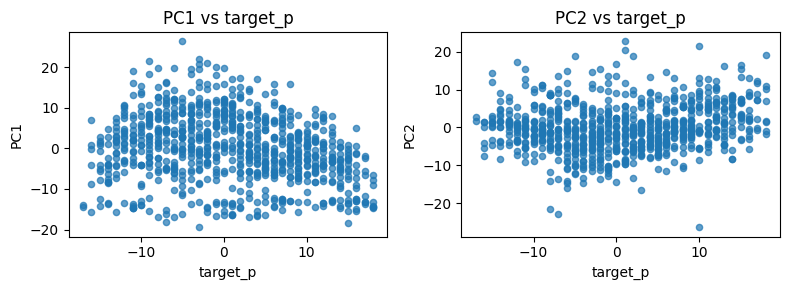

In [76]:
fig, axes = plt.subplots(1, 2, figsize=(8, 3))

axes[0].scatter(pca_meta["target_p"], pca_meta["PC1"], s=20, alpha=0.7)
axes[0].set_xlabel("target_p")
axes[0].set_ylabel("PC1")
axes[0].set_title("PC1 vs target_p")

axes[1].scatter(pca_meta["target_p"], pca_meta["PC3"], s=20, alpha=0.7)
axes[1].set_xlabel("target_p")
axes[1].set_ylabel("PC2")
axes[1].set_title("PC2 vs target_p")

plt.tight_layout()
plt.show()